In [3]:
%pip install torch

  Using cached torch-2.14.1-cp312-cp312-macosx_14_0_arm64.whl.metadata (38 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached markupsafe-3.0.4-cp312-cp312-macosx_11_0_arm64.whl.metadata (2.7 kB)
Using cached torch-2.14.1-cp312-cp312-macosx_14_0_arm64.whl (127.3 MB)
Using cached networkx-3.7-py3-none-any.whl (2.1 MB)
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
Using cached markupsafe-3.0.4-cp312-cp312-macosx_11_0_arm64.whl (12 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [torch]32m5/6 [torch]Safe]
Note: you may need to restart the kernel to use updated packages.


In [4]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Usamos CPU inicialmente para simplificar la ejecución.
device = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Dispositivo:", device)
print("Entorno listo para BiLSTM")

PyTorch: 2.14.1
Dispositivo: cpu
Entorno listo para BiLSTM


In [5]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)

Python: /opt/anaconda3/envs/poemas-ia/bin/python
PyTorch: 2.14.1


In [6]:
from datasets import load_dataset

dataset = load_dataset(
    "google-research-datasets/poem_sentiment"
)

CLASES = {
    0: "negative",
    1: "positive",
    2: "no_impact",
}

datos = {
    particion: dataset[particion].to_pandas().loc[
        lambda df: df["label"].isin(CLASES)
    ].copy()
    for particion in dataset
}

train_df = datos["train"]
val_df = datos["validation"]

print("Entrenamiento:", len(train_df))
print("Validación:", len(val_df))

/opt/anaconda3/envs/poemas-ia/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Entrenamiento: 843
Validación: 105


In [7]:
import re
from collections import Counter

def tokenizar(texto):
    # Conserva palabras, contracciones y signos de puntuación.
    return re.findall(r"\w+(?:'\w+)*|[^\w\s]", texto.lower())

frecuencias = Counter(
    token
    for texto in train_df["verse_text"]
    for token in tokenizar(texto)
)

PAD_ID = 0
UNK_ID = 1

vocabulario = {"<PAD>": PAD_ID, "<UNK>": UNK_ID}

for token in sorted(frecuencias):
    vocabulario[token] = len(vocabulario)

longitudes = [
    len(tokenizar(texto))
    for texto in train_df["verse_text"]
]

# Elegido solo a partir de entrenamiento.
MAX_LEN = max(1, int(np.ceil(np.percentile(longitudes, 95))))

print("Tamaño del vocabulario:", len(vocabulario))
print("Longitud máxima seleccionada:", MAX_LEN)
print("Ejemplo:", tokenizar(train_df.iloc[0]["verse_text"]))

Tamaño del vocabulario: 2225
Longitud máxima seleccionada: 13
Ejemplo: ['with', 'pale', 'blue', 'berries', '.', 'in', 'these', 'peaceful', 'shades', '-', '-']


In [8]:
from torch.utils.data import Dataset, DataLoader

class DatasetVersos(Dataset):
    def __init__(self, dataframe):
        self.textos = dataframe["verse_text"].tolist()
        self.etiquetas = dataframe["label"].tolist()

    def __len__(self):
        return len(self.textos)

    def __getitem__(self, indice):
        tokens = tokenizar(self.textos[indice])[:MAX_LEN]
        ids = [vocabulario.get(token, UNK_ID) for token in tokens]

        if not ids:
            ids = [UNK_ID]

        longitud = len(ids)
        ids += [PAD_ID] * (MAX_LEN - longitud)

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(longitud, dtype=torch.long),
            torch.tensor(self.etiquetas[indice], dtype=torch.long)
        )

generador = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    DatasetVersos(train_df),
    batch_size=32,
    shuffle=True,
    generator=generador
)

val_loader = DataLoader(
    DatasetVersos(val_df),
    batch_size=32,
    shuffle=False
)

ids, longitudes_lote, etiquetas = next(iter(train_loader))

print("Forma del lote:", ids.shape)
print("Longitudes:", longitudes_lote[:5])
print("Etiquetas:", etiquetas[:5])

Forma del lote: torch.Size([32, 13])
Longitudes: tensor([ 7, 11,  6,  6,  9])
Etiquetas: tensor([2, 2, 0, 2, 0])


In [9]:
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence

class BiLSTMClasificador(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim=100,
            padding_idx=PAD_ID
        )

        self.lstm = nn.LSTM(
            input_size=100,
            hidden_size=64,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(0.3)
        self.clasificador = nn.Linear(128, len(CLASES))

    def forward(self, ids, longitudes):
        embeddings = self.embedding(ids)

        secuencias = pack_padded_sequence(
            embeddings,
            longitudes.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(secuencias)

        # Estados finales de ambas direcciones.
        representacion = torch.cat(
            (hidden[-2], hidden[-1]),
            dim=1
        )

        return self.clasificador(
            self.dropout(representacion)
        )

torch.manual_seed(SEED)

modelo_lstm = BiLSTMClasificador(
    vocab_size=len(vocabulario)
).to(device)

print(
    "Parámetros entrenables:",
    sum(p.numel() for p in modelo_lstm.parameters()
        if p.requires_grad)
)

Parámetros entrenables: 307879


In [10]:
from copy import deepcopy
import pandas as pd
from sklearn.metrics import f1_score, classification_report

# Pesos calculados exclusivamente con entrenamiento.
conteos = (
    train_df["label"]
    .value_counts()
    .reindex(list(CLASES))
    .to_numpy()
)

pesos = len(train_df) / (len(CLASES) * conteos)

criterio = nn.CrossEntropyLoss(
    weight=torch.tensor(
        pesos, dtype=torch.float32, device=device
    )
)

optimizador = torch.optim.Adam(
    modelo_lstm.parameters(),
    lr=0.001
)

def evaluar_lstm(modelo, loader):
    modelo.eval()
    reales, predichas = [], []

    with torch.no_grad():
        for ids, longitudes, etiquetas in loader:
            logits = modelo(ids.to(device), longitudes)
            pred = logits.argmax(dim=1).cpu().tolist()

            predichas.extend(pred)
            reales.extend(etiquetas.tolist())

    f1 = f1_score(
        reales,
        predichas,
        labels=list(CLASES),
        average="macro",
        zero_division=0
    )

    return f1, reales, predichas

mejor_f1 = -1.0
mejor_estado = None
mejor_epoca = 0
sin_mejora = 0
historial = []

for epoca in range(1, 31):
    modelo_lstm.train()
    suma_perdidas = 0.0
    numero_lotes = 0

    for ids, longitudes, etiquetas in train_loader:
        ids = ids.to(device)
        etiquetas = etiquetas.to(device)

        optimizador.zero_grad()

        logits = modelo_lstm(ids, longitudes)
        perdida = criterio(logits, etiquetas)

        perdida.backward()
        nn.utils.clip_grad_norm_(
            modelo_lstm.parameters(), max_norm=1.0
        )
        optimizador.step()

        suma_perdidas += perdida.item()
        numero_lotes += 1

    f1_val, _, _ = evaluar_lstm(modelo_lstm, val_loader)
    perdida_media = suma_perdidas / numero_lotes

    historial.append({
        "epoca": epoca,
        "perdida_train": perdida_media,
        "f1_macro_val": f1_val
    })

    print(
        f"Época {epoca:02d} | "
        f"Loss train: {perdida_media:.4f} | "
        f"F1 val: {f1_val:.4f}"
    )

    if f1_val > mejor_f1:
        mejor_f1 = f1_val
        mejor_epoca = epoca
        mejor_estado = deepcopy(modelo_lstm.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1

    if sin_mejora >= 5:
        print("Detención temprana.")
        break

# Recuperar la mejor época, no la última.
modelo_lstm.load_state_dict(mejor_estado)

f1_lstm, reales_lstm, pred_lstm = evaluar_lstm(
    modelo_lstm, val_loader
)

print(f"\nMejor época: {mejor_epoca}")
print(f"Mejor F1 macro de validación: {f1_lstm:.4f}\n")

print(classification_report(
    reales_lstm,
    pred_lstm,
    labels=list(CLASES),
    target_names=list(CLASES.values()),
    digits=4,
    zero_division=0
))

Época 01 | Loss train: 1.1013 | F1 val: 0.3681
Época 02 | Loss train: 1.0448 | F1 val: 0.2975
Época 03 | Loss train: 0.9968 | F1 val: 0.3150
Época 04 | Loss train: 0.9031 | F1 val: 0.2979
Época 05 | Loss train: 0.7704 | F1 val: 0.3378
Época 06 | Loss train: 0.6026 | F1 val: 0.3811
Época 07 | Loss train: 0.4297 | F1 val: 0.3519
Época 08 | Loss train: 0.2707 | F1 val: 0.3282
Época 09 | Loss train: 0.1569 | F1 val: 0.3409
Época 10 | Loss train: 0.0881 | F1 val: 0.3531
Época 11 | Loss train: 0.0465 | F1 val: 0.3448
Detención temprana.

Mejor época: 6
Mejor F1 macro de validación: 0.3811

              precision    recall  f1-score   support

    negative     0.2692    0.3684    0.3111        19
    positive     0.2000    0.0588    0.0909        17
   no_impact     0.7162    0.7681    0.7413        69

    accuracy                         0.5810       105
   macro avg     0.3951    0.3985    0.3811       105
weighted avg     0.5518    0.5810    0.5581       105



In [11]:
from pathlib import Path
import json

salida = Path("artifacts/modelo_bilstm")
salida.mkdir(parents=True, exist_ok=True)

torch.save({
    "state_dict": modelo_lstm.state_dict(),
    "vocabulario": vocabulario,
    "clases": CLASES,
    "max_len": MAX_LEN,
    "pad_id": PAD_ID,
    "unk_id": UNK_ID,
    "embedding_dim": 100,
    "hidden_size": 64,
    "dropout": 0.3,
    "bidirectional": True
}, salida / "modelo.pt")

pd.DataFrame(historial).to_csv(
    salida / "historial.csv",
    index=False
)

registro = {
    "semilla": SEED,
    "mejor_epoca": mejor_epoca,
    "f1_macro_validacion": float(f1_lstm),
    "parametros_entrenables": sum(
        p.numel() for p in modelo_lstm.parameters()
        if p.requires_grad
    ),
    "pesos_clases": pesos.tolist(),
    "pytorch": str(torch.__version__),
    "reporte_validacion": classification_report(
        reales_lstm,
        pred_lstm,
        labels=list(CLASES),
        target_names=list(CLASES.values()),
        output_dict=True,
        zero_division=0
    ),
    "prueba_evaluada": False
}

with open(salida / "resultados.json", "w", encoding="utf-8") as archivo:
    json.dump(registro, archivo, ensure_ascii=False, indent=2)

predicciones_lstm = val_df[
    ["id", "verse_text", "label"]
].copy()

predicciones_lstm["prediccion"] = pred_lstm
predicciones_lstm.to_csv(
    salida / "predicciones_validacion.csv",
    index=False
)

print("Modelo y resultados guardados en:", salida.resolve())

Modelo y resultados guardados en: /Users/luisvazquez/Desktop/LAVP/Diplomado IA - CIC/PROYECTO_FINAL/Análisis de sentimientos en versos/poem-sentiment-v2/artifacts/modelo_bilstm


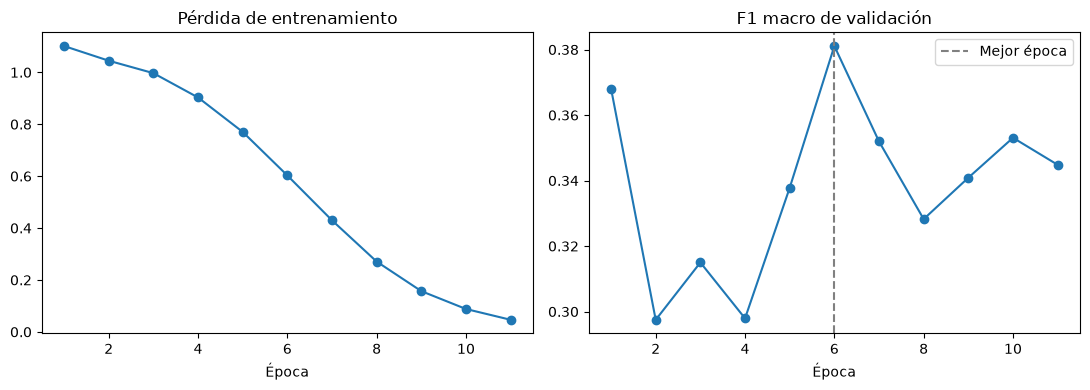

In [12]:
import matplotlib.pyplot as plt

historial_df = pd.DataFrame(historial)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    historial_df["epoca"],
    historial_df["perdida_train"],
    marker="o"
)
axes[0].set_title("Pérdida de entrenamiento")
axes[0].set_xlabel("Época")

axes[1].plot(
    historial_df["epoca"],
    historial_df["f1_macro_val"],
    marker="o"
)
axes[1].axvline(
    mejor_epoca, color="gray", linestyle="--",
    label="Mejor época"
)
axes[1].set_title("F1 macro de validación")
axes[1].set_xlabel("Época")
axes[1].legend()

plt.tight_layout()
plt.show()

In [13]:
print(historial_df.round(4).to_string(index=False))

 epoca  perdida_train  f1_macro_val
     1         1.1013        0.3681
     2         1.0448        0.2975
     3         0.9968        0.3150
     4         0.9031        0.2979
     5         0.7704        0.3378
     6         0.6026        0.3811
     7         0.4297        0.3519
     8         0.2707        0.3282
     9         0.1569        0.3409
    10         0.0881        0.3531
    11         0.0465        0.3448


Interpretación del entrenamiento. La BiLSTM obtuvo su mayor F1 macro de validación en la época 6 (0.3811). En las épocas posteriores, la pérdida de entrenamiento continuó disminuyendo, mientras que el F1 de validación fluctuó por debajo del máximo. Este comportamiento es compatible con sobreajuste. Se conservaron los pesos de la época 6 mediante selección por F1 macro de validación. En esta ejecución, la BiLSTM no superó al modelo TF–IDF con regresión logística ajustada (0.5509).

In [14]:
from pathlib import Path
import json
import pandas as pd
import torch
from datasets import load_dataset
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report

carpeta = Path("artifacts/modelo_bilstm")

checkpoint = torch.load(
    carpeta / "modelo.pt",
    map_location="cpu",
    weights_only=True
)

# Recuperar el preprocesamiento utilizado al entrenar.
vocabulario = checkpoint["vocabulario"]
CLASES = checkpoint["clases"]
MAX_LEN = checkpoint["max_len"]
PAD_ID = checkpoint["pad_id"]
UNK_ID = checkpoint["unk_id"]

device = torch.device("cpu")

modelo_lstm = BiLSTMClasificador(
    vocab_size=len(vocabulario)
).to(device)

modelo_lstm.load_state_dict(checkpoint["state_dict"])

dataset = load_dataset(
    "google-research-datasets/poem_sentiment"
)

test_df = dataset["test"].to_pandas().loc[
    lambda df: df["label"].isin(CLASES)
].copy()

test_loader = DataLoader(
    DatasetVersos(test_df),
    batch_size=32,
    shuffle=False
)

# Utiliza la función de evaluación definida antes.
f1_test_lstm, reales_test_lstm, pred_test_lstm = evaluar_lstm(
    modelo_lstm,
    test_loader
)

print(f"F1 macro de prueba: {f1_test_lstm:.4f}\n")

print(classification_report(
    reales_test_lstm,
    pred_test_lstm,
    labels=list(CLASES),
    target_names=list(CLASES.values()),
    digits=4,
    zero_division=0
))

ruta_registro = carpeta / "resultados.json"

with open(ruta_registro, encoding="utf-8") as archivo:
    registro = json.load(archivo)

registro.update({
    "prueba_evaluada": True,
    "f1_macro_prueba": float(f1_test_lstm),
    "reporte_prueba": classification_report(
        reales_test_lstm,
        pred_test_lstm,
        labels=list(CLASES),
        target_names=list(CLASES.values()),
        output_dict=True,
        zero_division=0
    )
})

with open(ruta_registro, "w", encoding="utf-8") as archivo:
    json.dump(registro, archivo, ensure_ascii=False, indent=2)

predicciones = test_df[["id", "verse_text", "label"]].copy()
predicciones["prediccion"] = pred_test_lstm
predicciones.to_csv(
    carpeta / "predicciones_test.csv",
    index=False
)

F1 macro de prueba: 0.4574

              precision    recall  f1-score   support

    negative     0.3158    0.3158    0.3158        19
    positive     0.5000    0.1875    0.2727        16
   no_impact     0.7342    0.8406    0.7838        69

    accuracy                         0.6442       104
   macro avg     0.5167    0.4480    0.4574       104
weighted avg     0.6217    0.6442    0.6197       104



In [15]:
from pathlib import Path
import json
import pandas as pd

carpetas = {
    "TF-IDF + Regresión logística": "modelo_clasico",
    "BiLSTM": "modelo_bilstm",
    "DistilBERT": "modelo_distilbert"
}

filas = []

for nombre, carpeta in carpetas.items():
    ruta = Path("artifacts") / carpeta / "resultados.json"

    with open(ruta, encoding="utf-8") as archivo:
        resultado = json.load(archivo)

    filas.append({
        "modelo": nombre,
        "f1_macro_validacion": resultado["f1_macro_validacion"],
        "f1_macro_prueba": resultado["f1_macro_prueba"],
        "accuracy_prueba": resultado["reporte_prueba"]["accuracy"]
    })

comparacion_final = pd.DataFrame(filas)

salida = Path("artifacts/comparacion")
salida.mkdir(parents=True, exist_ok=True)

comparacion_final.to_csv(
    salida / "resultados_finales.csv",
    index=False
)

display(comparacion_final.round(4))
print("Tabla comparativa guardada.")

,modelo,f1_macro_validacion,f1_macro_prueba,accuracy_prueba
0,TF-IDF + Regresión logística,0.5509,0.4400,0.6346
1,BiLSTM,0.3811,0.4574,0.6442
2,DistilBERT,0.8278,0.8140,0.8558


Tabla comparativa guardada.


In [16]:
from pathlib import Path
import pandas as pd

CLASES = {
    0: "negative",
    1: "positive",
    2: "no_impact"
}

for carpeta in ("modelo_clasico", "modelo_bilstm"):
    ruta = Path("artifacts") / carpeta / "predicciones_test.csv"
    predicciones = pd.read_csv(ruta)

    muestra = (
        predicciones.groupby("label", sort=True)
        .head(1)
        .copy()
    )

    muestra["real"] = muestra["label"].map(CLASES)
    muestra["prediccion_guardada"] = (
        muestra["prediccion"].map(CLASES)
    )

    print(f"\n{carpeta}")

    with pd.option_context("display.max_colwidth", None):
        display(muestra[
            ["verse_text", "real", "prediccion_guardada"]
        ])


modelo_clasico


,verse_text,real,prediccion_guardada
0,"my canoe to make more steady,",no_impact,no_impact
1,and be glad in the summer morning when the kindred ride on their way;,positive,positive
5,indignantly i hurled the cry:,negative,no_impact



modelo_bilstm


,verse_text,real,prediccion_guardada
0,"my canoe to make more steady,",no_impact,no_impact
1,and be glad in the summer morning when the kindred ride on their way;,positive,positive
5,indignantly i hurled the cry:,negative,no_impact
